# FD vs SEM — acoustic & elastic on a Gaussian-hill free surface

Two ways to put a wave solver on an **undulating free surface**, compared
side by side on the same Gaussian hill:

| | acoustic | elastic |
|---|---|---|
| **FD** (`PropTorch`) | `Acoustic`, image method (staircase + vacuum, Mittet 2002) | `ElasticCurvilinear` on a **boundary-fitted curvilinear grid** (Bartana, Xu & Rickett) |
| **SEM** (`PropSEM`) | `AcousticSEM2DDeformed` on a **body-fitted Quad9 mesh** | `ElasticVSSEM2DDeformed` (velocity-stress) on a body-fitted Quad9 mesh |

The acoustic FD method keeps the Cartesian grid and *snaps* the surface to
it, a staircase of vacuum cells; the elastic FD method maps the grid onto the
surface, so its top row is the hill; the SEM meshes **deform** their elements
so the edges follow the surface (the SPECFEM `NGNOD=9` curved-element idea).

Both solvers take the same call, `prop(wavelet, sources, receivers,
models=[...], return_wavefield=True, snapshot_times=[...])`: grid-index
sources and receivers, `source_type` / `receiver_type` by name, and the
absorbing layer padded outside the model. Topography is given the same way
too (see §1): a 1-D array `topography[ix]`, the surface **row** per column --
whole rows for the image method, the fractional surface for the curvilinear
grid and the SEM mesh.

We look at a wavefield snapshot and the surface seismogram gather for each.
Amplitudes are normalised per panel (the two backends scale their sources
differently), so the comparison is about **kinematics + waveform shape**, not
absolute amplitude.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.equations import Acoustic, ElasticCurvilinear
from sweep.propagator.torch import PropTorch
from sweep.signal import ricker
from sweep.sem import (PropSEM, AcousticSEM2DDeformed, ElasticVSSEM2DDeformed,
                       suggest_discretization)

DEV = "cuda" if torch.cuda.is_available() else "cpu"
# eager on CUDA would run its stencil convolutions in TF32 (~1e-4 off): keep FP32
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False
print("device:", DEV)

# ---- common physical setup (shared by FD and SEM) ----
X_MAX, Z_MAX = 1280.0, 900.0       # model (m)
DH = 5.0                           # model grid spacing, both solvers (m)
NX, NZ = int(round(X_MAX / DH)) + 1, int(round(Z_MAX / DH)) + 1
F0, DELAY = 12.0, 0.10             # Ricker
ABCN = 60                          # FD absorbing layers (300 m)
SEM_ABCN = 40                      # SEM C-PML cells: ten 20 m elements (200 m)
SNAP_T = 0.34                      # snapshot time to display (s)
SRC_DEPTH, REC_DEPTH = 40.0, 8.0   # below the local surface (m), both solvers

# velocities — acoustic vp; elastic vp/vs/rho
VP = 2200.0
VPE, VSE, RHOE = 2400.0, 1200.0, 2000.0

# The SEM resolution and a stable dt from the physics, instead of hand-tuning:
# the elastic shear speed sets the finest wavelength, vp_max sets the CFL.
# ppw=8 → comfortably over-resolved for clean snapshots.
disc = suggest_discretization(X_MAX, Z_MAX, v_min=VSE, v_max=VPE, f0=F0,
                              ppw=8.0, record_length=0.60)
print(disc)
SO, DT, NT = disc.n_order, disc.dt, disc.nt
# PropSEM tiles the model grid with elements of n_order cells, so the grid
# spacing carries the mesh: 5 m and order 4 give the 20 m elements asked for.
assert (NX - 1) // SO == disc.nex and (NZ - 1) // SO == disc.nez
# The FD side needs the 5 m as well: ~18 points in the 93 m Rayleigh
# wavelength at the 12 Hz peak, which the curvilinear free surface needs (at
# 10 m it would carry its own dispersion into the comparison).
print(f"grid: {NZ} x {NX} at {DH:.0f} m, SEM elements {SO * DH:.0f} m, "
      f"{0.93 * VSE / F0 / DH:.0f} points per Rayleigh wavelength at {F0:.0f} Hz")

# Gaussian hill, "down-positive depth" convention: z_top(x) is the depth of
# the surface below z = 0.  Crest rises to z = 0 at the centre; flat flanks
# sit HILL_BASE m deep.
HILL_BASE, X0, SIG = 50.0, X_MAX / 2.0, 150.0


def z_top_np(x):
    return HILL_BASE * (1.0 - np.exp(-((x - X0) ** 2) / (2.0 * SIG ** 2)))


device: cuda
SEMDiscretization(n_order=4, nex=64, nez=45, dt=4.30e-04, nt=1396  |  λ_min=40.0 m, h_e≈20×20 m, 8.0 pts/λ)
grid: 181 x 257 at 5 m, SEM elements 20 m, 19 points per Rayleigh wavelength at 12 Hz


## 1. The hill and the two topography conventions

**FD** wants a 1-D array — the surface **row index** per column.  The image
method needs whole rows, `topo_rows[ix] = round(z_top(x) / dh)`; the
curvilinear grid takes `z_top(x) / dh` itself, unrounded.  A *larger* value
means the surface is *deeper* (air occupies the rows above it), so the crest
(smallest depth) is the smallest row.

**SEM** takes the same fractional rows, `PropSEM(..., topography=topo_frac)`:
the top of its mesh passes through them at the element nodes, and is held flat
across the absorbing layer.

Source: 40 m below the crest.  Receivers: a line 8 m below the surface
that follows the topography.  Both solvers take them as grid indices
`[ix, iz]`: whole rows for the image method (§2), the exact depth below the
fractional surface for the curvilinear grid and the SEM mesh (§3).

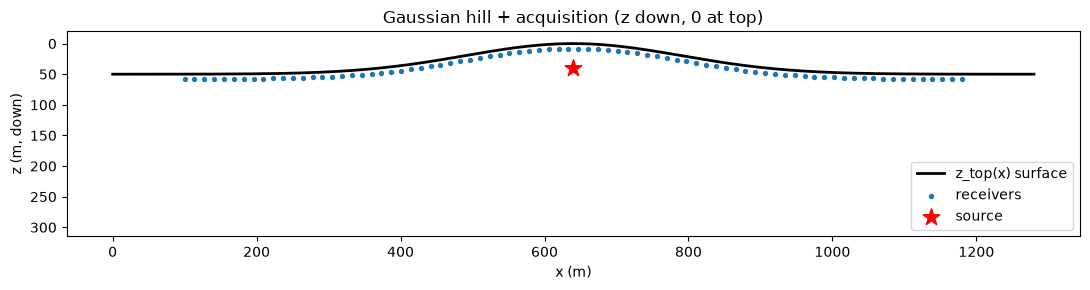

In [2]:
xg = np.arange(NX) * DH
topo_rows = np.round(z_top_np(xg) / DH).astype(np.int64)   # image method: whole rows
topo_frac = z_top_np(xg) / DH                               # curvilinear: the surface itself
rec_x = np.linspace(100.0, X_MAX - 100.0, 80)              # receiver x (m)
src_x = X0                                                 # source x (crest)
t = np.arange(NT) * DT - DELAY
wav_np = ricker(t, f=F0).astype(np.float32)

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(xg, z_top_np(xg), "k", lw=2, label="z_top(x) surface")
ax.scatter(rec_x, z_top_np(rec_x) + REC_DEPTH, c="C0", s=8, label="receivers")
ax.scatter([src_x], [z_top_np(src_x) + SRC_DEPTH], c="r", marker="*",
           s=160, label="source")
ax.set_ylim(Z_MAX * 0.35, -20)     # z down-positive, 0 at top
ax.set_xlabel("x (m)"); ax.set_ylabel("z (m, down)")
ax.set_title("Gaussian hill + acquisition (z down, 0 at top)")
ax.legend(loc="lower right"); fig.tight_layout(); plt.show()

### Shared plotting helpers

Both solvers return their snapshots on the grid of the model and its
absorbing layer -- `PropSEM` evaluates its field at every grid point through
the element's basis -- so the helpers crop the layer and mask the air above
the surface, and the two wavefields are shown on the same axes.

In [3]:
ZQ = np.arange(NZ)[:, None] * DH
ZTOP = z_top_np(np.arange(NX) * DH)
AIR = ZQ < ZTOP[None, :]


def mask_air(img):
    img = img.copy(); img[AIR] = np.nan
    return img


def sem_on_model(snap):
    """A PropSEM snapshot on its grid -- the model and its absorbing layer,
    none on the free top -- cropped to the model, the air masked."""
    return mask_air(snap[:NZ, SEM_ABCN:SEM_ABCN + NX])


def compare(fd_w, sem_w, fd_g, sem_g, title, wlabels=("FD", "SEM")):
    fig, ax = plt.subplots(2, 2, figsize=(14, 7.5))
    for a, img, lab in [(ax[0, 0], fd_w, wlabels[0]), (ax[0, 1], sem_w, wlabels[1])]:
        v = np.nanpercentile(np.abs(img), 99)
        a.imshow(img, extent=[0, X_MAX, Z_MAX, 0], aspect="auto", cmap="seismic",
                 vmin=-v, vmax=v)
        a.plot(xg, ZTOP, "k", lw=1.2)
        a.set_title(f"{lab} wavefield @ t={SNAP_T}s")
        a.set_xlabel("x (m)"); a.set_ylabel("z (m)")
    for a, g, lab in [(ax[1, 0], fd_g, wlabels[0]), (ax[1, 1], sem_g, wlabels[1])]:
        gm = g / max(np.abs(g).max(), 1e-30)
        a.imshow(gm.T, extent=[rec_x[0], rec_x[-1], NT * DT, 0], aspect="auto",
                 cmap="gray", vmin=-0.08, vmax=0.08)
        a.set_title(f"{lab} gather"); a.set_xlabel("receiver x (m)"); a.set_ylabel("t (s)")
    fig.suptitle(title, fontsize=13); fig.tight_layout(); plt.show()


## 2. Acoustic — FD (image) vs SEM (Quad9)

FD: `Acoustic` + `topo_method='image'` (the only acoustic option; the
surface is a per-column vacuum/image row).  SEM: `AcousticSEM2DDeformed` on
a deformed Quad9 mesh with a pressure-release top; `abcn=40` adds a
ten-element C-PML outside the sides and bottom, as FD's `abcn` does.  Both take the same source and receiver indices and record the
pressure, `receiver_type=["p"]`.

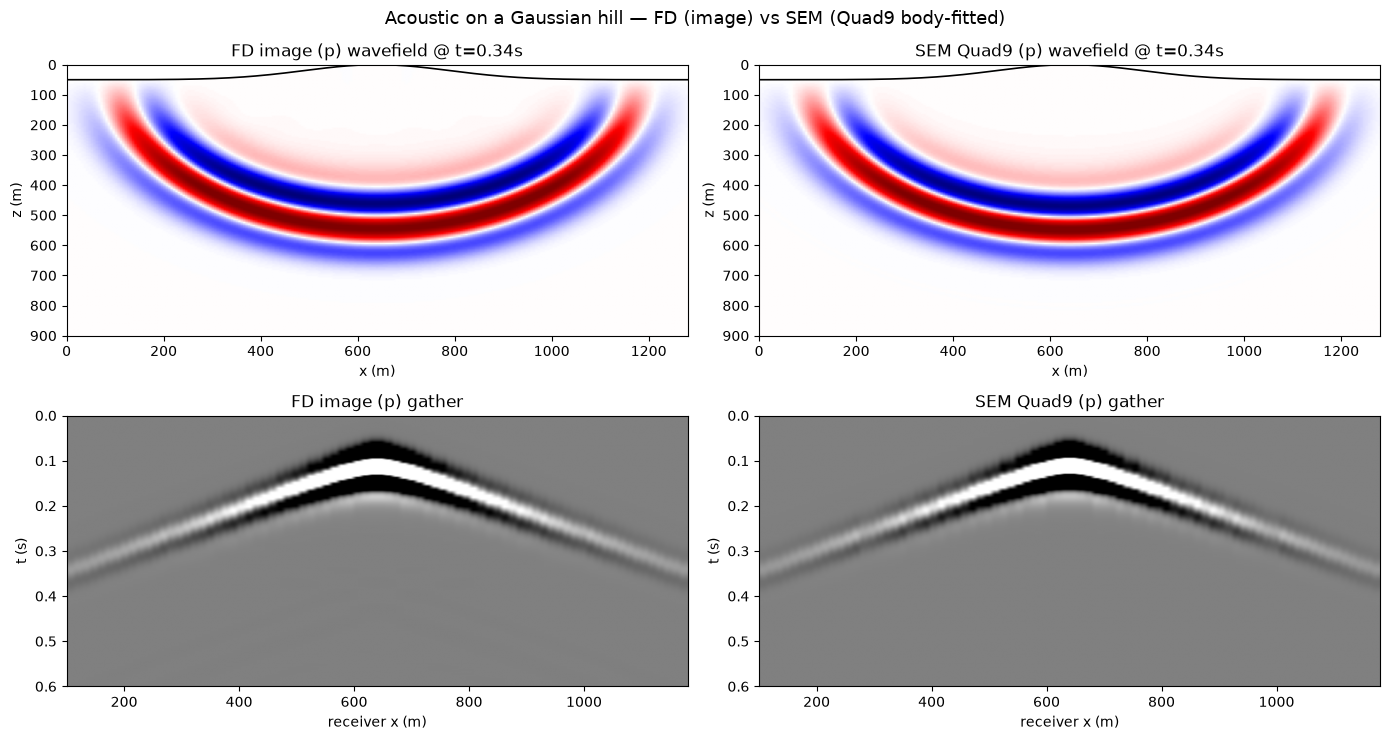

In [4]:
def run_fd_acoustic():
    eq = Acoustic(spatial_order=SO, device=DEV, backend="torch")
    prop = PropTorch(eq, shape=(NZ, NX), topography=topo_rows, topo_method="image",
                     abcn=ABCN, dh=DH, dt=DT, impl="eager", use_ckpt=False,
                     eager_options={"use_compile": False})
    vp = torch.full((NZ, NX), VP, dtype=torch.float32, device=DEV)
    wav = torch.tensor(wav_np, device=DEV)
    syn, snaps = prop(wav, SRC_AC, REC_AC, models=[vp], return_wavefield=True,
                      snapshot_times=[int(round(SNAP_T / DT))])
    gather = syn[0, :, :, 0].detach().cpu().numpy().T
    wfield = snaps[0, 0, 0, 0].detach().cpu().numpy()[:-ABCN, ABCN:-ABCN]  # image: top kept
    return mask_air(wfield), gather


def run_sem_acoustic():
    prop = PropSEM(AcousticSEM2DDeformed, shape=(NZ, NX), dh=DH, dt=DT,
                   n_order=SO, topography=topo_frac, abcn=SEM_ABCN,
                   f_dominant=F0, device=DEV, impl="eager", receiver_type=["p"])
    vp = torch.full((NZ, NX), VP, dtype=torch.float32, device=DEV)
    wav = torch.tensor(wav_np, device=DEV)
    seis, snaps = prop(wav, SRC_AC, REC_AC, models=[vp], return_wavefield=True,
                       snapshot_times=[int(round(SNAP_T / DT))])
    gather = seis[0, :, :, 0].cpu().numpy().T          # (nrec, nt), as the FD gathers
    return sem_on_model(snaps[0, 0, 0, 0].numpy()), gather


# one set of grid indices [ix, iz] for both: the image method's whole rows
sc = int(round(src_x / DH))
rcol = np.round(rec_x / DH).astype(np.int64)
SRC_AC = torch.tensor([[sc, int(topo_rows[sc]) + int(round(SRC_DEPTH / DH))]])
REC_AC = torch.tensor(np.stack([rcol, topo_rows[rcol] + int(round(REC_DEPTH / DH))], -1)[None])

with torch.no_grad():
    fd_w, fd_g = run_fd_acoustic()
    sem_w, sem_g = run_sem_acoustic()
compare(fd_w, sem_w, fd_g, sem_g,
        "Acoustic on a Gaussian hill — FD (image) vs SEM (Quad9 body-fitted)",
        wlabels=("FD image (p)", "SEM Quad9 (p)"))

The acoustic wavefronts and the topographic move-out in the gather match
closely — the crest receivers fire earliest (the surface bows up toward the
source), giving the characteristic "tent" gather in both backends.

## 3. Elastic — FD (curvilinear) vs SEM (Quad9)

FD: `ElasticCurvilinear` (eager) on a boundary-fitted grid whose top row is
the hill: collocated fields, asymmetric operators and a rotated traction-free
surface.  Its sources and receivers are physical grid indices, as for every
method; the propagator maps them onto its rows.  SEM: the **1st-order
velocity-stress** `ElasticVSSEM2DDeformed`, whose C-PML `PropSEM` builds and
pads outside the model as in §2, with a natural traction-free top.

Both are driven by the same `source_type=["sxx", "szz"]`, an explosion, and
record `receiver_type=["vz"]`, the vertical particle velocity.  FD adds the
wavelet to the two normal stresses every step, which makes the wavelet the
moment *rate*; `PropSEM` drives its moment-tensor load with the wavelet's
running integral, so the same name and the same wavelet give the same
waveform on both.

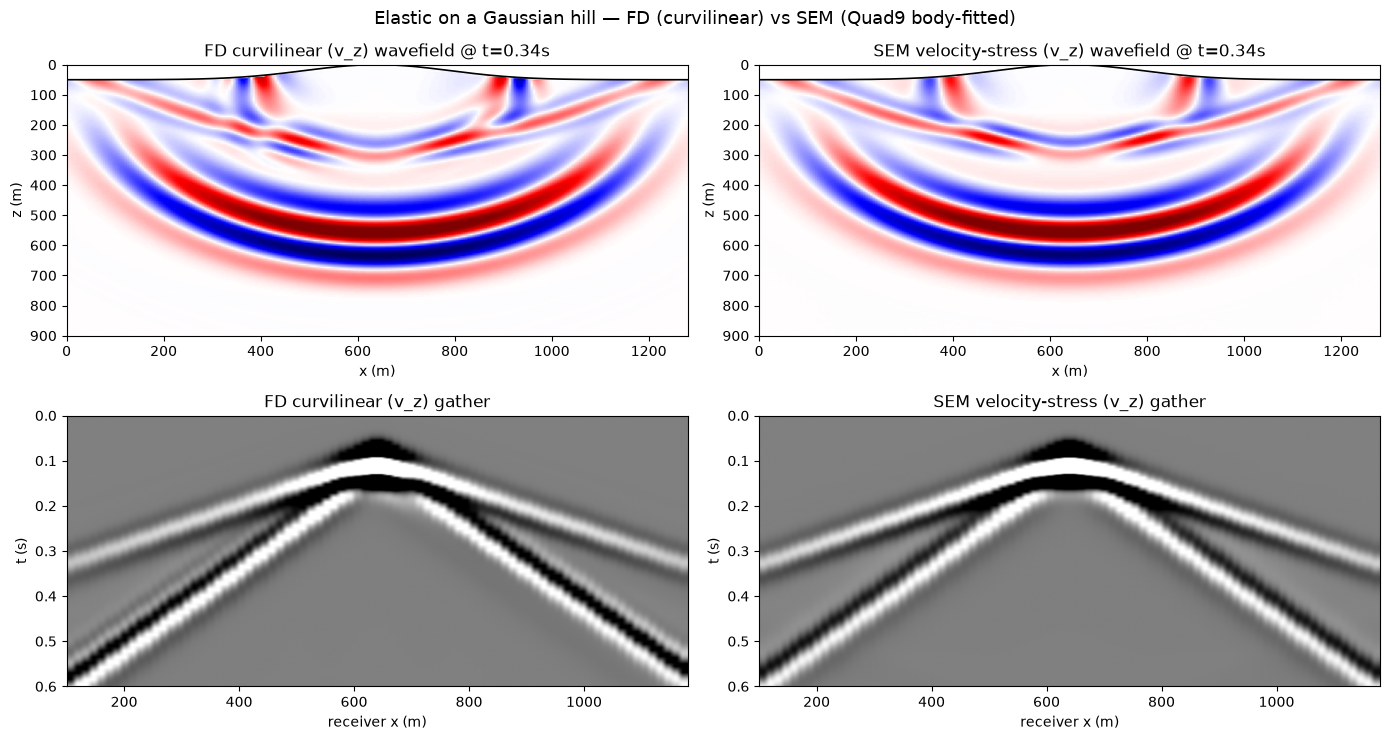

In [5]:
def run_fd_elastic():
    eq = ElasticCurvilinear(spatial_order=SO, device=DEV, backend="torch")
    prop = PropTorch(eq, shape=(NZ, NX), topography=topo_frac, abcn=ABCN,
                     dh=DH, dt=DT, impl="eager", use_ckpt=False,
                     eager_options={"use_compile": False},
                     source_type=["sxx", "szz"], receiver_type=["vz"])
    vp = torch.full((NZ, NX), VPE, dtype=torch.float32, device=DEV)
    vs = torch.full((NZ, NX), VSE, dtype=torch.float32, device=DEV)
    rho = torch.full((NZ, NX), RHOE, dtype=torch.float32, device=DEV)
    # physical grid indices, the exact depths below the fractional surface: the
    # propagator maps them onto its boundary-fitted rows
    src = torch.tensor([[sc, topo_frac[sc] + SRC_DEPTH / DH]])
    rec = torch.tensor(np.stack([rcol, topo_frac[rcol] + REC_DEPTH / DH], -1)[None])
    wav = torch.tensor(wav_np, device=DEV)
    syn, snaps = prop(wav, src, rec, models=[vp, vs, rho], return_wavefield=True,
                      snapshot_times=[int(round(SNAP_T / DT))])
    gather = syn[0, :, :, 0].detach().cpu().numpy().T
    # the snapshot comes back on the physical grid, zero in the air
    k = prop.wavefield_names.index("vz")
    vz = snaps[0, k, 0, 0].detach().cpu().numpy()[:NZ, ABCN:ABCN + NX]  # top PML suppressed
    return mask_air(vz), gather


def run_sem_elastic():
    prop = PropSEM(ElasticVSSEM2DDeformed, shape=(NZ, NX), dh=DH, dt=DT,
                   n_order=SO, topography=topo_frac, abcn=SEM_ABCN,
                   f_dominant=F0, device=DEV, impl="eager",
                   source_type=["sxx", "szz"], receiver_type=["vz"])
    models = [torch.full((NZ, NX), v, dtype=torch.float32, device=DEV)
              for v in (VPE, VSE, RHOE)]
    # the same physical grid indices as the curvilinear run, fractional rows
    src = torch.tensor([[sc, topo_frac[sc] + SRC_DEPTH / DH]])
    rec = torch.tensor(np.stack([rcol, topo_frac[rcol] + REC_DEPTH / DH], -1)[None])
    wav = torch.tensor(wav_np, device=DEV)
    seis, snaps = prop(wav, src, rec, models=models, return_wavefield=True,
                       snapshot_times=[int(round(SNAP_T / DT))])
    gather = seis[0, :, :, 0].cpu().numpy().T
    return sem_on_model(snaps[0, 0, 0, 0].numpy()), gather


with torch.no_grad():
    fd_we, fd_ge = run_fd_elastic()
    sem_we, sem_ge = run_sem_elastic()
compare(fd_we, sem_we, fd_ge, sem_ge,
        "Elastic on a Gaussian hill — FD (curvilinear) vs SEM (Quad9 body-fitted)",
        wlabels=("FD curvilinear (v_z)", "SEM velocity-stress (v_z)"))

With the same explosion on both, the two agree in waveform as well as in
timing: the P wavefront, the waves the flanks of the hill send down and the
surface wave in the gathers fall in the same places with the same polarity.
The curvilinear grid and the deformed mesh both put the free surface on the
hill itself, with no staircase.  Each panel is normalised on its own, so the
amplitudes are not compared.

## 4. Notes

- **Topography input.** Both take a per-column surface-row array: whole rows
  `round(z_top/dh)` for the image method, `z_top/dh` for the curvilinear
  grid and the SEM mesh.  Larger value = deeper surface, so a hill is a
  *minimum* at the centre.
- **Body-fitted vs grid.** SEM elements deform to follow the surface
  (`NGNOD=9` curved geometry).  The acoustic FD run keeps a Cartesian grid
  and approximates the surface with a staircase; the elastic FD run maps its
  grid onto the surface and hands its snapshots back on the Cartesian grid,
  and the SEM runs evaluate their field at the grid points through each
  element's basis.
- **Resolution + CFL (no hand-tuning).** `n_order` and `dt` come from
  `suggest_discretization(...)`: ~`ppw` GLL points per shortest wavelength
  (`λ_min = v_min / f_max`) sets the element size, and a CFL-safe `dt` on the
  smallest GLL spacing sets the step (the clustered GLL nodes make the SEM
  `dt` tighter than FD's).  `PropSEM` builds elements of `n_order` grid
  cells, so the grid spacing is what carries the element size.
- **Absorbing edges.** Both SEM runs add a C-PML of `abcn=40` cells -- ten
  elements, 200 m -- outside the sides and the bottom, as FD pads its `abcn`
  layers, so the receivers can span the model.  The elastic run uses
  the 1st-order velocity-stress form, whose single-stage C-PML stays stable
  over long records (the 2nd-order displacement C-PML does not, in this port).
- **Sources.** The same `source_type` means the same source on both
  backends: `["sxx", "szz"]` an explosion, `["vz"]` a vertical force
  (the wavelet is the force), `["sxz"]` a shear moment.  Their amplitude
  scales differ — FD adds the wavelet to a field at one grid point, SEM
  assembles a weak-form load on the GLL nodes — so panels are normalised
  independently: compare move-out and waveform shape, not absolute amplitude.
- **Acoustic SEM on topography** uses `AcousticSEM2DDeformed` (this repo's
  Quad9 scalar acoustic); it reduces bit-for-bit to the flat-mesh
  `AcousticSEM2D` on an axis-aligned Quad9.

---

<p><strong>Download this notebook</strong> &mdash; <a href="41_fd_vs_sem_topography.ipynb" download><code>41_fd_vs_sem_topography.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/41_fd_vs_sem_topography.ipynb">view on GitHub</a></p>